# 1.2 Distribution of Variables and Statistics

**Merged version** (MIZ + team) — section 1.2 only.

Contents:
- 1.2.1 Summary of statistics
- 1.2.2 Distribution via histograms
- 1.2.3 Distribution via pie chart
- 1.2.4 Distribution via bar chart


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

df = pd.read_csv('dataset/seller_info_dm1_2627.csv')
print('Shape:', df.shape)


Shape: (13843, 33)


### 1.2.1 Summary of statistics


In [2]:
# Numeric summary + skewness, kurtosis and IQR (identifier excluded)
num_cols = df.select_dtypes(include=[np.number]).drop(columns=['sp_id']).columns.tolist()

stats_df = df[num_cols].describe().T
stats_df['skew'] = df[num_cols].skew()
stats_df['kurtosis'] = df[num_cols].kurtosis()
stats_df['iqr'] = stats_df['75%'] - stats_df['25%']

stats_df.round(2)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,iqr
n_listings,13843.0,118.10,137.06,5.00,25.00,70.00,168.00,4959.00,5.25,120.32,143.00
price_median,13843.0,23106.14,14365.07,1699.00,12495.00,22385.00,29888.00,236438.00,3.45,34.14,17393.00
savings_amount_median,13843.0,446.21,519.46,0.00,0.00,358.00,734.00,9333.00,2.40,18.30,734.00
daysonmarket_median,13843.0,49.15,56.06,0.00,26.00,36.00,51.00,1987.00,8.75,168.60,25.00
mileage_median,13842.0,51463.27,51845.46,0.00,25.00,33596.50,96915.75,238541.00,0.68,-0.77,96890.75
year_median,13843.0,2015.95,4.72,1960.00,2013.00,2017.00,2020.00,2021.00,-2.25,14.09,7.00
vehicle_age_median,13842.0,4.08,4.63,0.00,0.00,3.00,7.00,60.00,2.32,14.98,7.00
owner_count_median,13804.0,1.43,0.62,1.00,1.00,1.00,2.00,6.00,1.30,1.35,1.00
horsepower_median,13837.0,240.90,56.99,78.00,188.00,243.00,283.00,630.00,0.85,2.05,95.00
engine_displacement_median,10450.0,2925.08,808.08,1200.00,2400.00,2500.00,3500.00,6800.00,1.29,2.77,1100.00


In [3]:
# Categorical summary (missing values shown explicitly)
def print_column_with_percentage(df, column_name):
    counts = df[column_name].value_counts(dropna=False)
    counts.index = [('missing' if pd.isna(i) else i) for i in counts.index]
    percentages = (counts / counts.sum() * 100).round(2)
    result = (pd.DataFrame({'Count': counts, 'Percentage': percentages})
              .sort_values(by='Count', ascending=False))
    print(result)

for col in df.select_dtypes(include='str').columns:
    print(f'Column: {col}')
    print_column_with_percentage(df, col)
    print()


Column: dominant_body_type
               Count  Percentage
suv_crossover   8920       64.44
sedan           3044       21.99
pickup_truck    1424       10.29
coupe            167        1.21
hatchback         97        0.70
van               82        0.59
convertible       63        0.46
minivan           39        0.28
wagon              7        0.05

Column: dominant_fuel_type
                   Count  Percentage
gasoline           13658       98.66
flex_fuel_vehicle     91        0.66
diesel                52        0.38
biodiesel             16        0.12
hybrid                13        0.09
electric              12        0.09
unknown                1        0.01

Column: dominant_transmission
         Count  Percentage
a        12976       93.74
cvt        847        6.12
m           14        0.10
unknown      6        0.04

Column: dominant_wheel_system
         Count  Percentage
missing  10518       75.98
fwd       1781       12.87
awd        724        5.23
4wd        668

#### Key insights (1.2.1)

- **No constant variables**, but `pct_salvage` and `pct_theft_title` are **zero-inflated**
  (25%, 50%, 75% all = 0) with extreme right skew (10.3 / 14.1): most sellers have clean
  titles, while a small niche specialises in salvage/theft vehicles.
- **Severe scale disparity**: `pct_*` ∈ [0, 1] and legroom varies by < 1 in, whereas
  `mileage_median` spans 0–238k and `price_median` 1.7k–236k → motivates scaling (§1.4).
- **Missingness is concentrated**: `dominant_wheel_system` 76.0% and
  `engine_displacement_median` 24.5%; all other columns have < 0.3% missing.
- **Target is imbalanced**: medium 54.7%, high 26.6%, low 18.6% → use stratified splits
  and Macro-F1 in classification.


### 1.2.2 Distribution via histograms


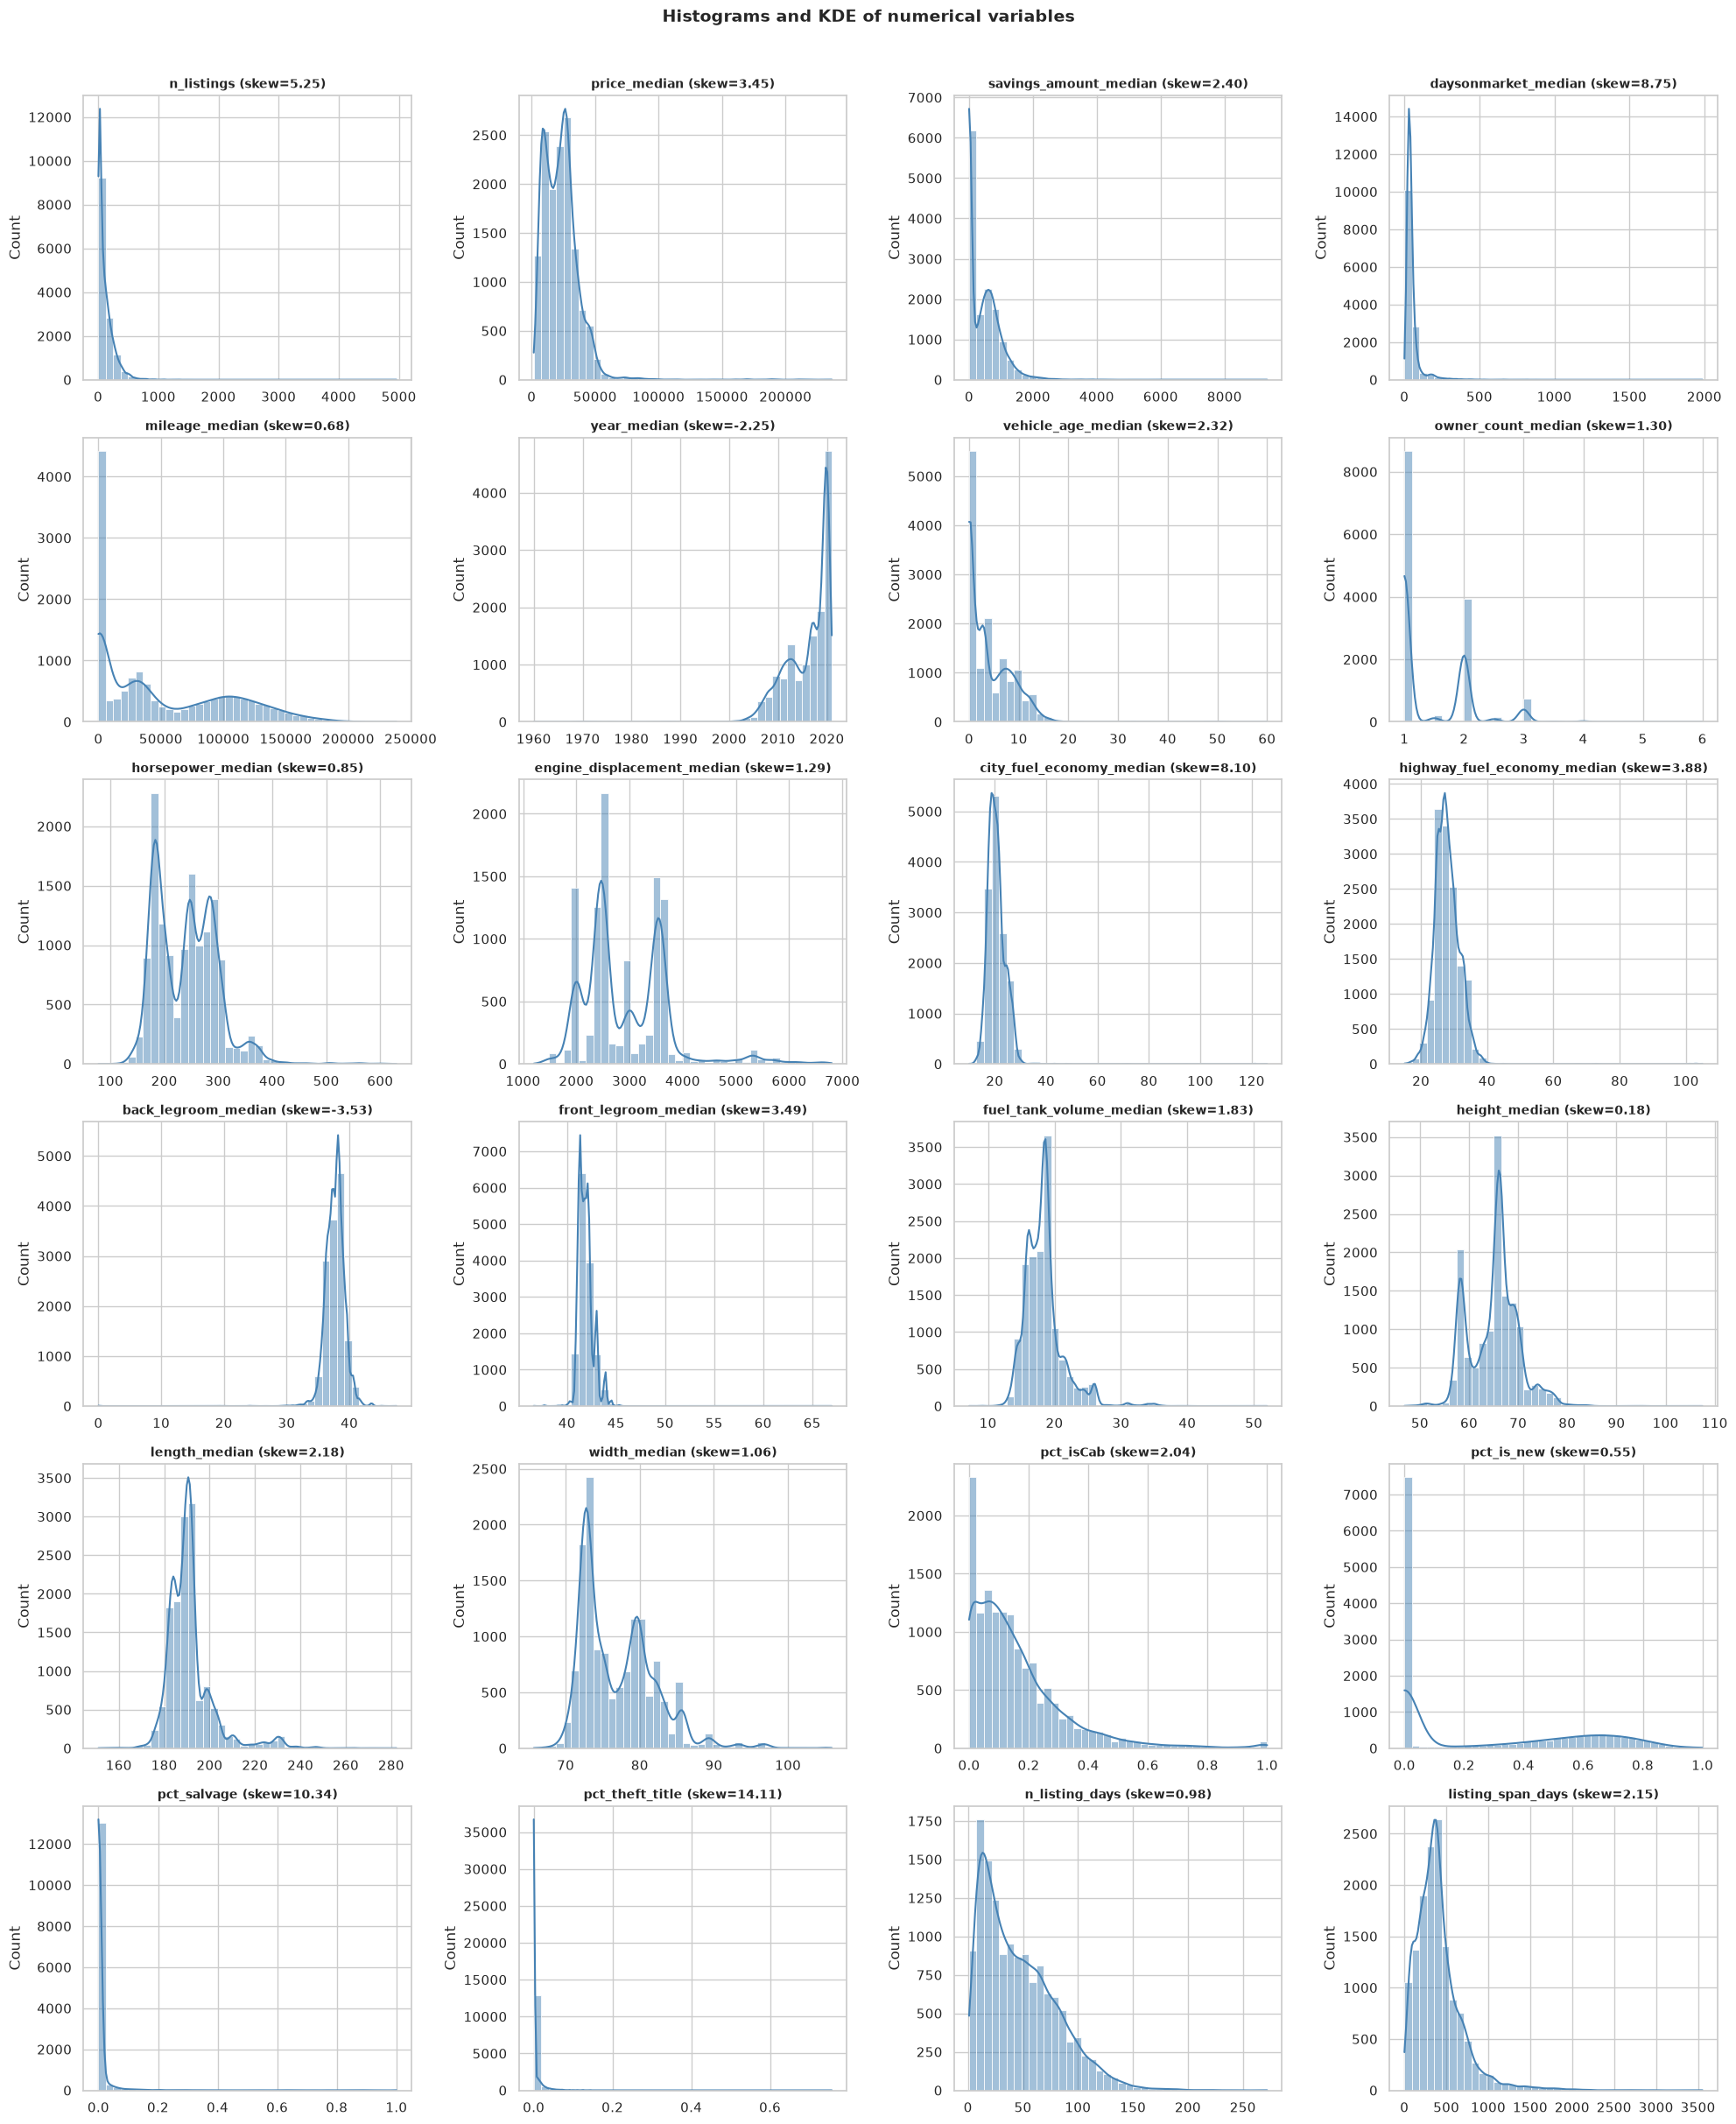

In [4]:
# All numeric histograms with KDE and skewness in the title
fig, axes = plt.subplots(6, 4, figsize=(20, 24))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=40, ax=axes[i], color='steelblue')
    axes[i].set_title(f'{col} (skew={df[col].skew():.2f})', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')

for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')

plt.suptitle('Histograms and KDE of numerical variables', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

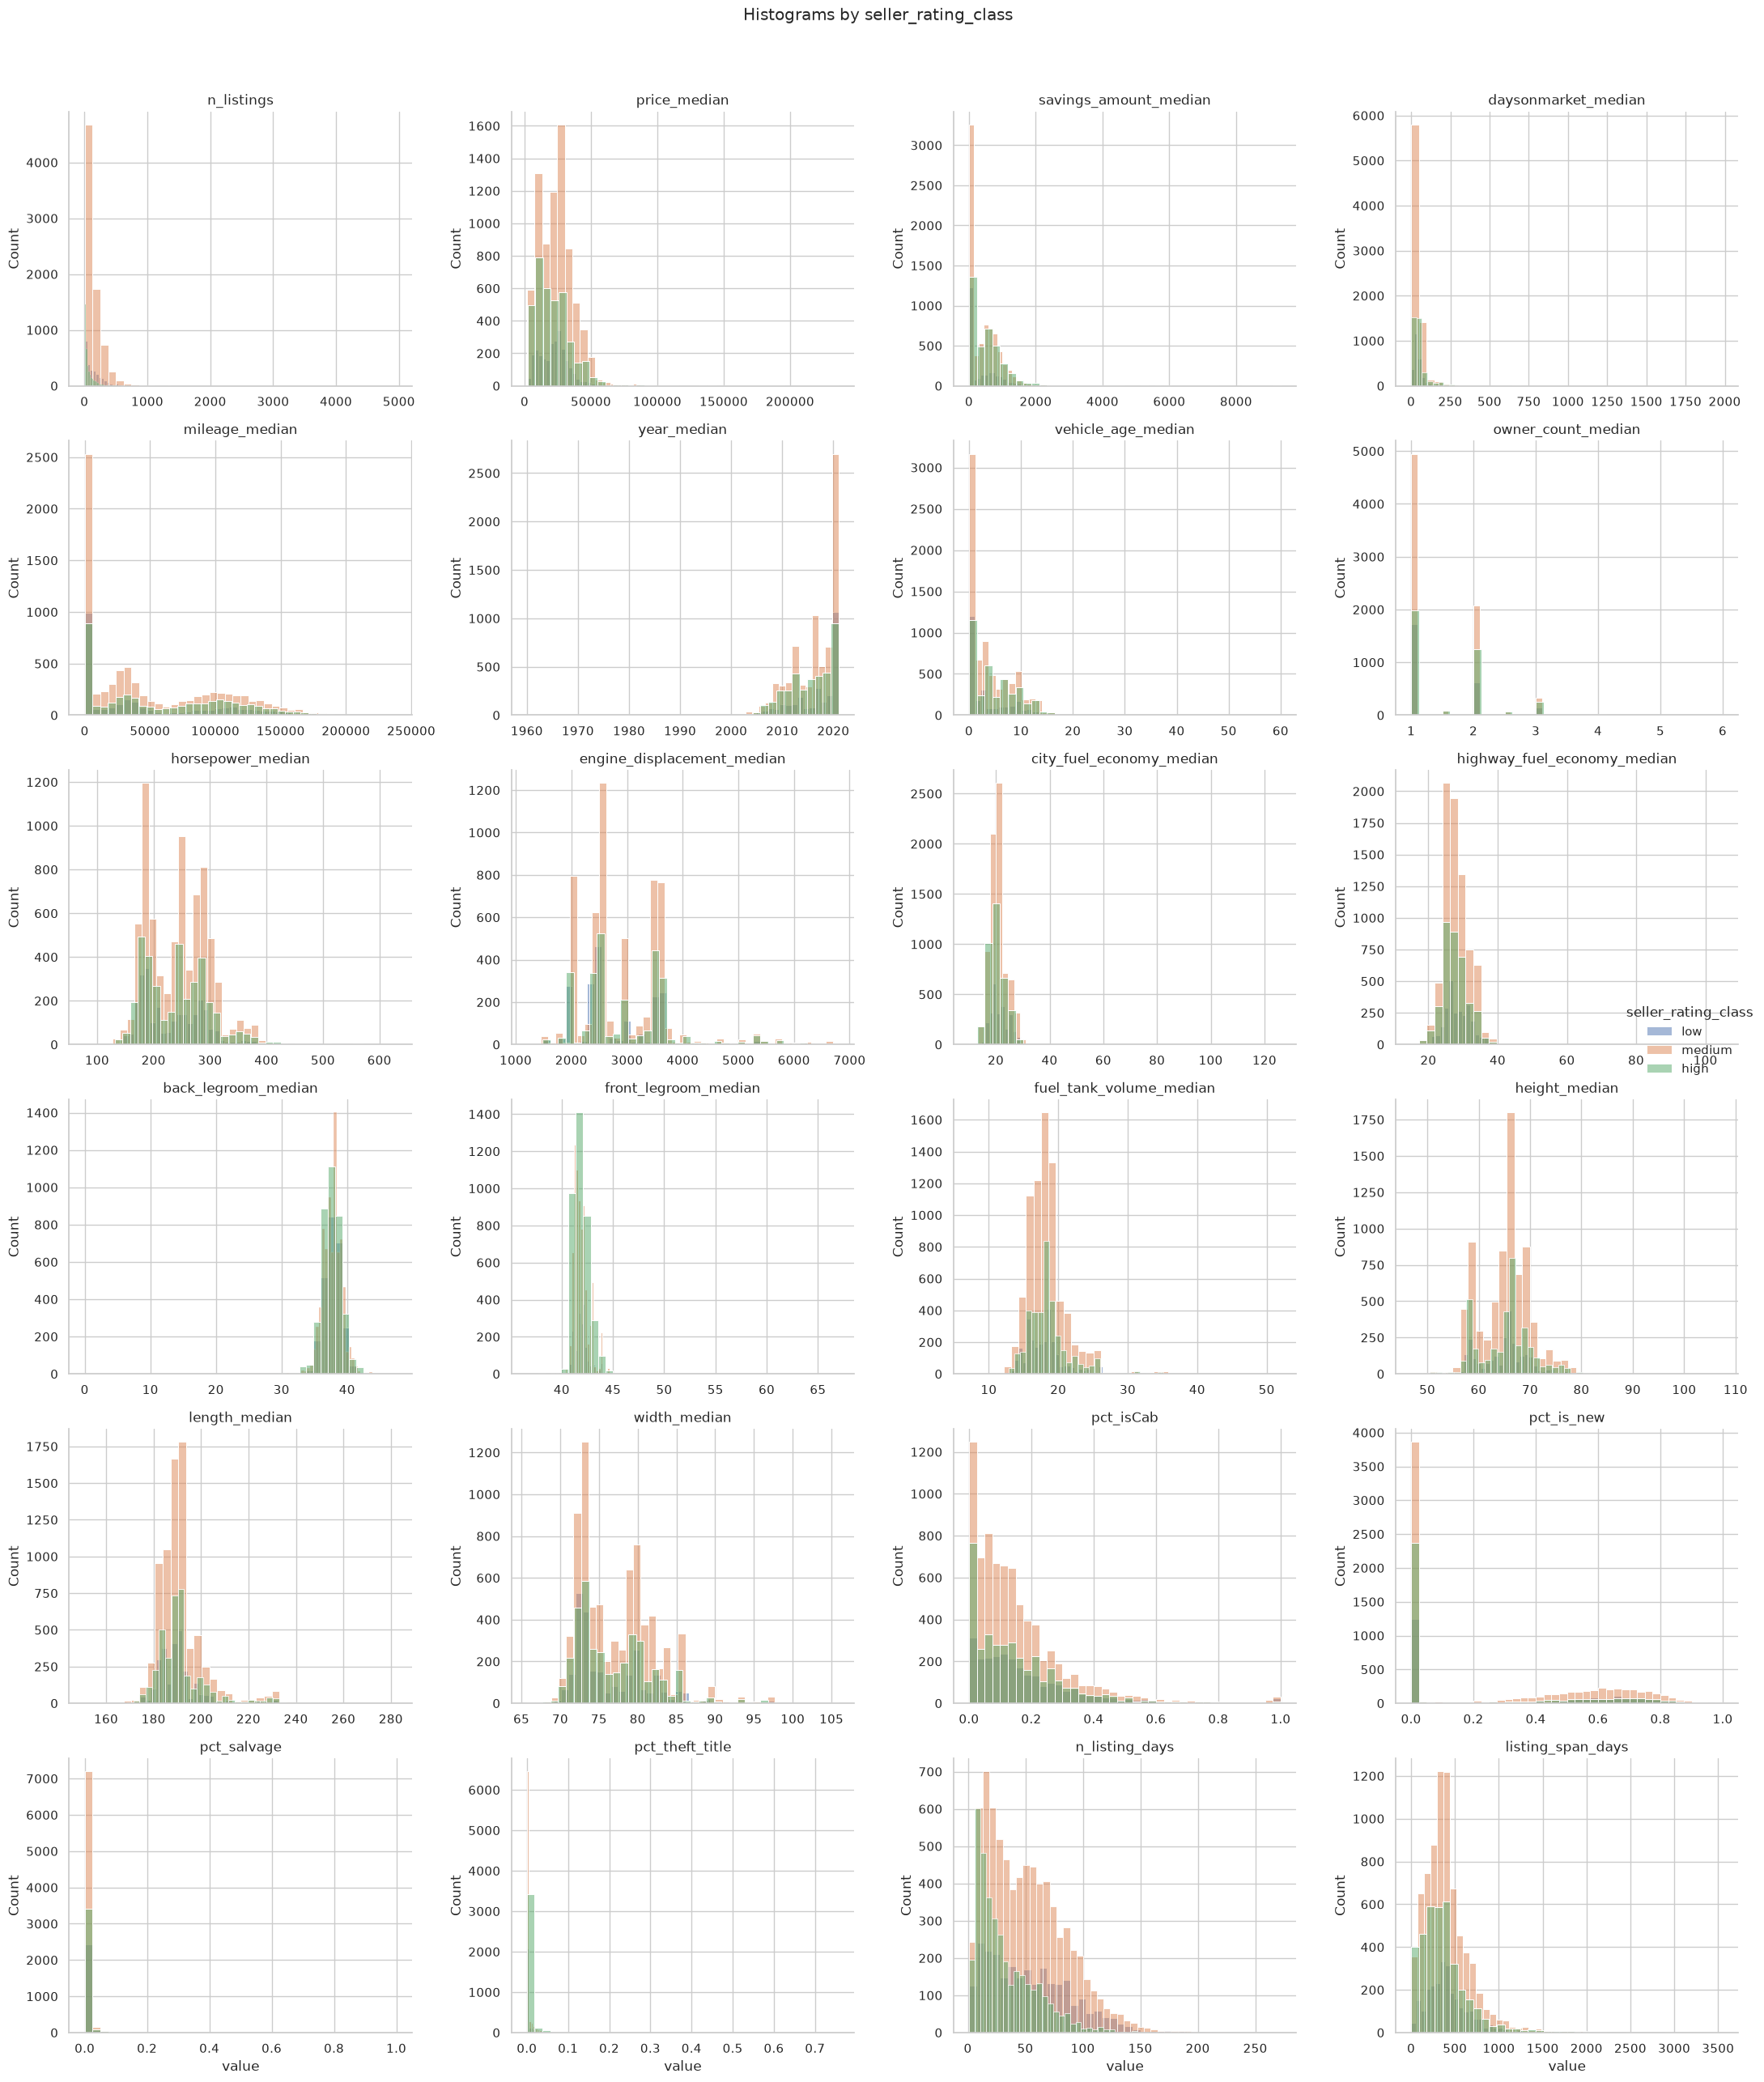

In [5]:
# Same distributions split by the target class
plot_df = df[num_cols + ['seller_rating_class']].melt(
    id_vars='seller_rating_class', var_name='variable', value_name='value')

g = sns.FacetGrid(
    plot_df, col='variable', col_wrap=4,
    hue='seller_rating_class', hue_order=['low', 'medium', 'high'],
    sharex=False, sharey=False, height=4.2, aspect=1.2,
)
g.map_dataframe(
    sns.histplot, x='value', bins=40, multiple='layer', alpha=0.5,
    palette={'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'},
)
g.add_legend(title='seller_rating_class')
g.set_titles('{col_name}')
g.figure.suptitle('Histograms by seller_rating_class', y=1.02)
plt.tight_layout()
plt.show()


#### Key insights (1.2.2)

- **Bimodality (new vs used)**: `mileage_median` and `pct_is_new` show a spike at 0
  (new cars) separated from a broad used-car distribution (30k–120k miles).
- **Lease-return peak**: `vehicle_age_median` has a secondary peak at **3 years**
  (off-lease vehicles) beside the new-car peak at 0.
- **Multimodal engineering**: `engine_displacement_median` clusters around **2.0–2.5 L**
  (4-cylinder) and **3.5–6.0 L** (V6/V8/trucks).
- **Heavy right skew / outliers** in `price_median`, `daysonmarket_median`,
  `mileage_median`, `n_listings`, `listing_span_days` and `pct_*` → handled in §1.3.2 / §1.4.


### 1.2.3 Distribution via pie chart


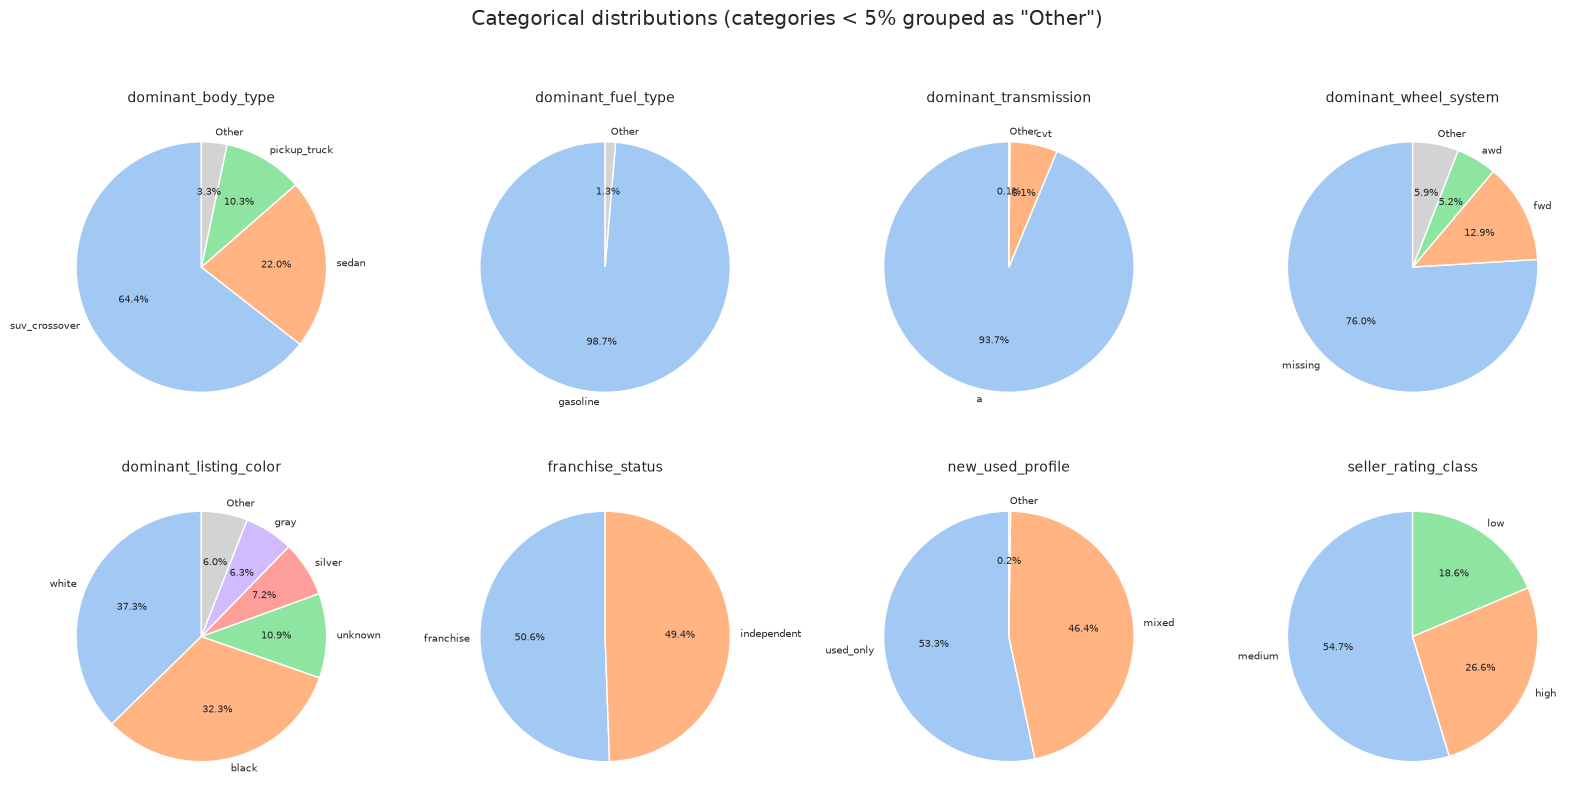

In [6]:
# Pie chart for every categorical variable; categories < 5% are grouped as "Other"
categorical_cols = df.select_dtypes(include='str').columns.tolist()
MIN_PCT = 5.0

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, categorical_cols):
    vc = df[col].value_counts(dropna=False)
    vc.index = [('missing' if pd.isna(i) else i) for i in vc.index]

    pct = vc / vc.sum() * 100
    keep = vc[pct >= MIN_PCT].copy()
    other = vc[pct < MIN_PCT].sum()
    if other > 0:
        keep.loc['Other'] = other

    labels = list(keep.index)
    colors = list(sns.color_palette('pastel', n_colors=len(labels)))
    if 'Other' in labels:
        colors[labels.index('Other')] = 'lightgray'

    ax.pie(keep.values, labels=labels, colors=colors, autopct='%1.1f%%',
           startangle=90, wedgeprops={'edgecolor': 'white'},
           textprops={'fontsize': 7}, labeldistance=1.08)
    ax.set_title(col, fontsize=10)

for ax in axes[len(categorical_cols):]:
    ax.axis('off')

plt.suptitle('Categorical distributions (categories < 5% grouped as "Other")', y=1.02)
plt.tight_layout()
plt.show()


#### Key insights (1.2.3)

- **Target imbalance**: medium 54.7%, high 26.6%, low 18.6%.
- **Franchise vs independent** is almost 50/50 (50.6% / 49.4%).
- **Used-only 53.3% vs mixed 46.4%**, while new_only is only 0.2% (31 sellers).
- **Body type is dominated by SUVs/crossovers (64.4%)**, then sedans (22.0%) and pickups (10.3%).
- **Fuel type is almost entirely gasoline (98.7%)**; electric/hybrid/diesel are < 1%.
- `dominant_wheel_system` is 76% missing → not usable for modelling (drop in §1.3.1).


### 1.2.4 Distribution via bar chart


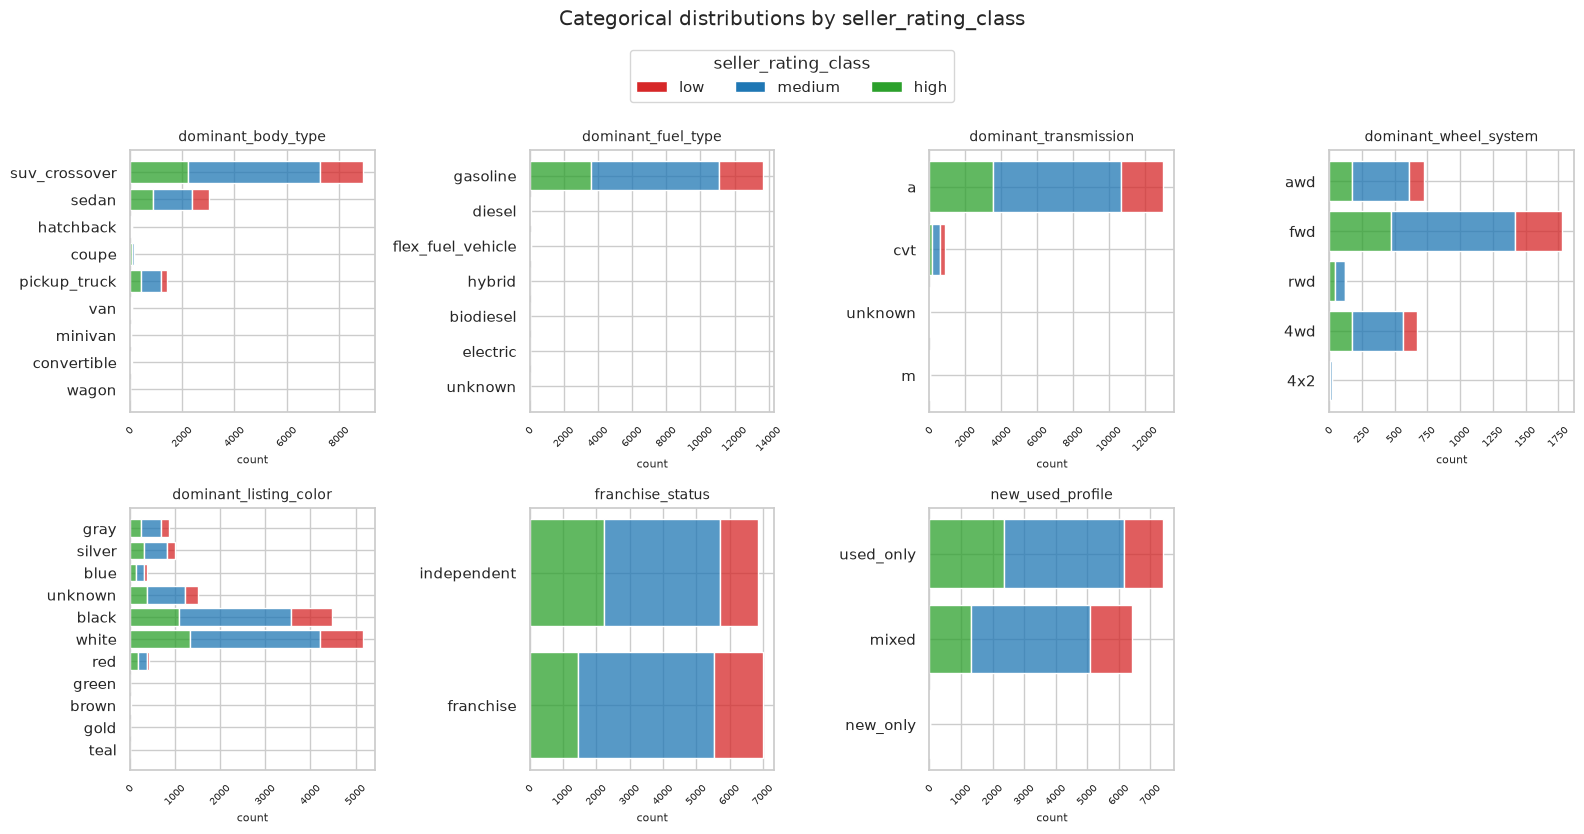

In [7]:
from matplotlib.patches import Patch

# Stacked horizontal bars: category counts split by seller_rating_class
hue_order = ['low', 'medium', 'high']
palette = {'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'}
plot_cols = [c for c in categorical_cols if c != 'seller_rating_class']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, plot_cols):
    sns.histplot(
        data=df, y=col,
        hue='seller_rating_class', hue_order=hue_order,
        multiple='stack', palette=palette,
        ax=ax, shrink=0.8, legend=False,
    )
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.set_ylabel('')
    ax.set_xlabel('count', fontsize=8)

for ax in axes[len(plot_cols):]:
    ax.axis('off')

handles = [Patch(facecolor=palette[k], label=k) for k in hue_order]
fig.legend(handles=handles, loc='upper center', ncol=3,
           title='seller_rating_class', bbox_to_anchor=(0.5, 1.0))
plt.suptitle('Categorical distributions by seller_rating_class', y=1.04)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


#### Key insights (1.2.4)

- **Category concentration is strong**: SUVs/crossovers 64%, gasoline 99%,
  automatic transmission 94%, and white/black/gray colours ~76%.
- **Rating differs across categories**: independent and used-only sellers have a higher
  share of `high` ratings than franchise/mixed sellers; niche body types (convertible,
  minivan, hatchback) also skew high, but the groups are small.
- **Rare categories** (wagon, electric, new_only, 4x2) should be grouped as `Other`
  before one-hot encoding to avoid sparse columns.


---

**Note:** section 1.2 stops here (descriptive distributions only). Outlier/missing handling
is in §1.3, transformations in §1.4, and correlation-based feature analysis in §1.5.
